# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [ ]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


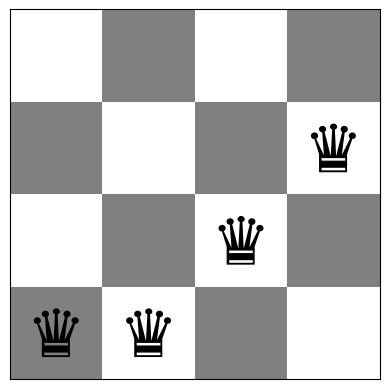

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [2]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


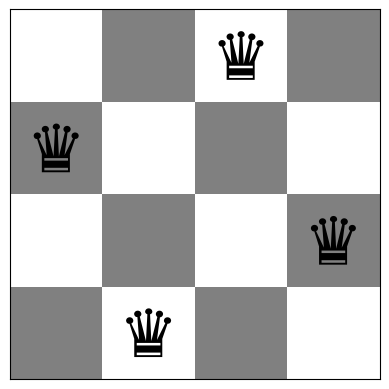

In [3]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

Bàn đầu: [5 3 4 0 7 1 3 5], conflicts = 5
Bàn cuối: [5 3 6 0 7 1 4 2], conflicts = 0, số bước = 4, số lần gọi conflicts = 225
Board with 0 conflicts.


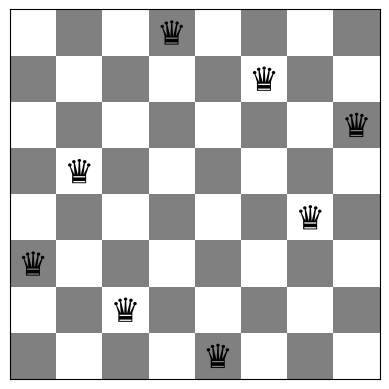

In [4]:
import time, math
import pandas as pd
from IPython.display import display

def steepest_ascent(board, max_iter=1000):
    """Steepest-ascent HC: đánh giá mọi nước đi lân cận (n*(n-1) nước), chọn nước giảm conflicts nhiều nhất.
    Nếu nhiều nước bằng nhau thì chọn ngẫu nhiên. Dừng khi không còn nước nào cải thiện."""
    board = np.array(board).copy()
    n = len(board)
    f = conflicts(board); evals = 1; steps = 0
    history = [f]                                   # f sau mỗi bước (dùng để vẽ hội tụ)
    while f > 0 and steps < max_iter:
        best_f, best_moves = f, []
        for col in range(n):
            orig = board[col]
            for row in range(n):
                if row == orig: continue
                board[col] = row
                nf = conflicts(board); evals += 1
                if nf < best_f:                      # tốt hơn hẳn -> làm lại danh sách
                    best_f, best_moves = nf, [(col, row)]
                elif nf == best_f and best_moves:    # bằng nước tốt nhất hiện tại -> thêm vào
                    best_moves.append((col, row))
            board[col] = orig                        # trả quân hậu về chỗ cũ
        if not best_moves: break                     # cực trị cục bộ
        col, row = best_moves[np.random.randint(len(best_moves))]
        board[col] = row; f = best_f; steps += 1; history.append(f)
    return {"board": board, "f": f, "steps": steps, "evals": evals, "history": history}

# Ví dụ
np.random.seed(1)
b0 = random_board(8)
res = steepest_ascent(b0)
print(f"Bàn đầu: {b0}, conflicts = {conflicts(b0)}")
print(f"Bàn cuối: {res['board']}, conflicts = {res['f']}, số bước = {res['steps']}, số lần gọi conflicts = {res['evals']}")
show_board(res["board"], fontsize=24)

### Mô tả cách cài đặt (Task 1)

* **Trạng thái:** vector `board` độ dài n, `board[c]` là hàng của quân hậu ở cột c (mỗi cột đúng một quân).
* **Lân cận:** dời một quân hậu sang hàng khác trong cùng cột, tức n·(n−1) nước đi (n = 8: 56 nước).
* **Chọn nước:** tính `conflicts()` cho *mọi* lân cận, chọn nước cho f nhỏ nhất. Nếu nhiều nước bằng nhau thì chọn ngẫu nhiên để không luôn đi cùng một hướng.
* **Dừng:** khi không có lân cận nào có f nhỏ hơn f hiện tại (cực trị cục bộ, có thể là f > 0), hoặc f = 0.
* **Chi phí:** mỗi bước tốn n(n−1) lần gọi `conflicts()` (mỗi lần O(n)), nên mỗi bước là O(n³).
* Hàm trả về `history` (f sau mỗi bước) và `evals` (số lần gọi `conflicts()`), dùng cho Task 6.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [5]:
def stochastic_inefficient(board, max_iter=1000):
    """Stochastic HC (liệt kê mọi nước): mỗi bước tính mọi lân cận, gom các nước CẢI THIỆN rồi chọn ngẫu nhiên 1 nước."""
    board = np.array(board).copy()
    n = len(board)
    f = conflicts(board); evals = 1; steps = 0
    history = [f]
    while f > 0 and steps < max_iter:
        better = []
        for col in range(n):
            orig = board[col]
            for row in range(n):
                if row == orig: continue
                board[col] = row
                nf = conflicts(board); evals += 1
                if nf < f: better.append((col, row, nf))
            board[col] = orig
        if not better: break                         # không có nước cải thiện -> cực trị cục bộ
        col, row, f = better[np.random.randint(len(better))]
        board[col] = row; steps += 1; history.append(f)
    return {"board": board, "f": f, "steps": steps, "evals": evals, "history": history}

np.random.seed(1)
b0 = random_board(8)
res = stochastic_inefficient(b0)
print(f"conflicts: {conflicts(b0)} -> {res['f']}, số bước = {res['steps']}, số lần gọi conflicts = {res['evals']}")

conflicts: 5 -> 1, số bước = 4, số lần gọi conflicts = 281


### Mô tả cách cài đặt (Task 2)

Giống Task 1 (vẫn tính toàn bộ n(n−1) lân cận ở mỗi bước) nhưng gom **mọi** nước cải thiện (f mới < f hiện tại) rồi chọn **ngẫu nhiên** một nước, thay vì chọn nước tốt nhất. Chi phí mỗi bước bằng Steepest-ascent, nhưng đường đi đa dạng hơn và thường cần nhiều bước hơn (xem Task 6). Ví dụ trên dừng ở f = 1, tức là kẹt ở cực trị cục bộ.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [6]:
def default_patience(n):
    """Số lần thử liên tiếp không cải thiện trước khi dừng.
    Có N = n(n-1) nước đi lân cận, lấy mẫu có hoàn lại. Sau k lần thử, kỳ vọng số nước chưa được thử là N*exp(-k/N).
    Chọn k = 2*N*ln(N) -> kỳ vọng chưa thử ~ 1/N < 1, tức là hầu như đã thử hết mọi lân cận."""
    N = n * (n - 1)
    return int(2 * N * math.log(N))

def stochastic_efficient(board, patience=None, max_iter=100000):
    """First-choice / Stochastic HC: sinh MỘT lân cận ngẫu nhiên, nhận nếu tốt hơn.
    Dừng khi f = 0, hoặc `patience` lần thử liên tiếp không cải thiện (coi là cực trị cục bộ)."""
    board = np.array(board).copy()
    n = len(board)
    if patience is None: patience = default_patience(n)
    f = conflicts(board); evals = 1; steps = 0; fails = 0; it = 0
    history = [f]                                    # f sau mỗi lần THỬ
    while f > 0 and fails < patience and it < max_iter:
        it += 1
        col = np.random.randint(n)                   # chọn ngẫu nhiên 1 cột
        row = np.random.randint(n - 1)               # chọn ngẫu nhiên hàng khác hàng hiện tại
        if row >= board[col]: row += 1
        old = board[col]; board[col] = row
        nf = conflicts(board); evals += 1
        if nf < f: f = nf; steps += 1; fails = 0     # chấp nhận
        else: board[col] = old; fails += 1           # hoàn tác
        history.append(f)
    return {"board": board, "f": f, "steps": steps, "iters": it, "evals": evals, "history": history}

np.random.seed(1)
b0 = random_board(8)
res = stochastic_efficient(b0)
print(f"patience (n=8) = {default_patience(8)}")
print(f"conflicts: {conflicts(b0)} -> {res['f']}, số bước chấp nhận = {res['steps']}, số lần thử = {res['iters']}")

patience (n=8) = 450
conflicts: 5 -> 0, số bước chấp nhận = 5, số lần thử = 72


### Mô tả cách cài đặt và chọn `patience` (Task 3)

Mỗi lần thử chỉ sinh **một** lân cận ngẫu nhiên (chọn cột ngẫu nhiên, chọn hàng mới ngẫu nhiên khác hàng cũ) và chấp nhận nếu f giảm; nếu không thì hoàn tác. Vì không bao giờ duyệt hết lân cận nên cần tiêu chí dừng: dừng sau `patience` lần thử **liên tiếp** không cải thiện (bộ đếm được reset mỗi khi có cải thiện).

**Chọn `patience`:** có N = n(n−1) lân cận, lấy mẫu có hoàn lại. Sau k lần thử, xác suất một lân cận cụ thể chưa được thử là (1 − 1/N)^k ≈ e^(−k/N), nên kỳ vọng số lân cận chưa thử là N·e^(−k/N). Chọn k = 2·N·ln N thì kỳ vọng này ≈ 1/N < 1, tức là gần như đã thử hết mọi lân cận. Với n = 8 ta có patience = 450, với n = 20 là khoảng 4500.

Lưu ý: `history` của hàm này ghi f sau **mỗi lần thử** (không chỉ mỗi nước được chấp nhận), nên đoạn nằm ngang ở cuối đồ thị chính là `patience` lần thử thất bại.

In [7]:
# Bài 3: đo chi phí của 3 biến thể Hill Climbing (MỘT lần chạy, không restart)
# Cả 3 thuật toán chạy trên cùng một bàn cờ ngẫu nhiên (seed 0) để so sánh công bằng.
# Trung bình của 100 lần chạy (ổn định hơn) xem ở Task 6.
def measure_hc(algo, n, seed=0):
    np.random.seed(seed)
    board = random_board(n)
    t0 = time.perf_counter()
    r = algo(board)
    ms = (time.perf_counter() - t0) * 1000
    return {"f đầu": conflicts(board), "f cuối": r["f"], "Số bước chấp nhận": r["steps"],
            "Số lần gọi conflicts()": r["evals"], "Thời gian (ms)": ms}

hc3 = {"Steepest asc. HC (Task 1)": steepest_ascent,
       "Stochastic - mọi nước (Task 2)": stochastic_inefficient,
       "Stochastic - lân cận ngẫu nhiên (Task 3)": stochastic_efficient}
rows = [{"Algorithm": name, "n": n, **measure_hc(fn, n)} for n in (4, 8) for name, fn in hc3.items()]
display(pd.DataFrame(rows).round(2))

,Algorithm,n,f đầu,f cuối,Số bước chấp nhận,Số lần gọi conflicts(),Thời gian (ms)
0,Steepest asc. HC (Task 1),4,2,1,1,25,0.17
1,Stochastic - mọi nước (Task 2),4,2,1,1,25,0.13
2,Stochastic - lân cận ngẫu nhiên (Task 3),4,2,1,1,61,0.55
3,Steepest asc. HC (Task 1),8,7,1,3,225,1.77
4,Stochastic - mọi nước (Task 2),8,7,1,5,337,2.56
5,Stochastic - lân cận ngẫu nhiên (Task 3),8,7,3,3,460,6.15


### Nhận xét Bài 3: đánh đổi giữa chất lượng và chi phí

Bảng trên là **một lần chạy** của mỗi thuật toán, cùng bàn cờ ban đầu (seed 0). Cột *Số lần gọi `conflicts()`* là thước đo chi phí không phụ thuộc máy; thời gian (ms) chỉ để tham khảo vì dao động theo tải máy.

* **Chi phí giải thích được bằng công thức.** Với Steepest và Stochastic (mọi nước), mỗi lần quét toàn bộ lân cận tốn n(n−1) lần gọi (n = 8: 56). Steepest ở n = 8 đi 3 bước rồi quét thêm một lần nữa để xác nhận kẹt: 1 + 4×56 = 225. Stochastic (mọi nước) đi 5 bước nên 1 + 6×56 = 337. Ở n = 4 (12 lân cận), 1 bước và 1 lần quét xác nhận cho 1 + 2×12 = 25.
* **Stochastic (lân cận ngẫu nhiên)** chỉ tốn 1 lần gọi cho mỗi lần thử, nhưng phải chờ `patience` lần thử thất bại liên tiếp mới kết luận đã kẹt (n = 4: 59, n = 8: 450). Do đó nó tốn nhiều lần gọi nhất (61 ở n = 4, 460 ở n = 8) dù chỉ chấp nhận vài bước. Phần lớn chi phí là để xác nhận bị kẹt.
* **Chất lượng:** trong lần chạy này cả ba đều kẹt ở cực trị cục bộ (f cuối > 0). Với n = 8, Steepest và Stochastic (mọi nước) dừng ở f = 1, còn Stochastic (lân cận ngẫu nhiên) dừng ở f = 3. Một lần chạy không đủ để kết luận thuật toán nào tốt hơn, vì kết quả phụ thuộc bàn cờ ban đầu và ngẫu nhiên. Trung bình 100 lần chạy ở Task 6 cho thấy chất lượng của ba thuật toán gần như bằng nhau (17–20% thành công ở n = 8).
* **Kết luận đánh đổi:** chọn nước tốt nhất (Steepest) cho mỗi bước tốt nhưng mỗi bước tốn nhiều lần đánh giá; chọn ngẫu nhiên giảm chi phí mỗi bước nhưng cần nhiều bước hơn hoặc cần tiêu chí dừng (`patience`). Chất lượng cuối cùng không khác nhau đáng kể, nên thuật toán rẻ nhất (Steepest ở n nhỏ) là lựa chọn hợp lý cho đến khi kết hợp với Random Restart (Task 4).

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [8]:
def random_restart(algo, n, max_restarts=100, **kw):
    """Chạy `algo` từ bàn cờ ngẫu nhiên mới, tối đa max_restarts lần; dừng sớm khi tìm được f = 0.
    Trả về kết quả tốt nhất; evals/steps được cộng dồn qua mọi lần khởi động."""
    best = None; evals = 0; steps = 0
    for r in range(1, max_restarts + 1):
        res = algo(random_board(n), **kw)
        evals += res["evals"]; steps += res["steps"]
        if best is None or res["f"] < best["f"]: best = res
        if best["f"] == 0: break
    return {**best, "evals": evals, "steps": steps, "restarts": r}

def test_restart(base_algo, n, reps=100, seed=0):
    rows = []
    for i in range(reps):
        np.random.seed(seed + i)
        t0 = time.perf_counter()
        res = random_restart(base_algo, n)
        rows.append({"ms": (time.perf_counter() - t0) * 1000, "f": res["f"], "restarts": res["restarts"]})
    d = pd.DataFrame(rows)
    return {"Avg. time (ms)": d.ms.mean(), "Avg. best f": d.f.mean(),
            "% optimal": 100 * (d.f == 0).mean(), "Avg. restarts": d.restarts.mean(), "Max restarts": d.restarts.max()}

base = {"Steepest asc. HC": steepest_ascent, "Ineff. Stochastic HC": stochastic_inefficient,
        "Efficient Stochastic HC": stochastic_efficient}
rows = []
for n in (4, 8):
    for name, fn in base.items():
        rows.append({"Algorithm + restart": name, "n": n, **test_restart(fn, n)})
display(pd.DataFrame(rows).round(2))

,Algorithm + restart,n,Avg. time (ms),Avg. best f,% optimal,Avg. restarts,Max restarts
0,Steepest asc. HC,4,0.36,0.0,100.0,2.31,15
1,Ineff. Stochastic HC,4,0.51,0.0,100.0,2.74,20
2,Efficient Stochastic HC,4,1.76,0.0,100.0,3.24,15
3,Steepest asc. HC,8,13.88,0.0,100.0,6.74,29
4,Ineff. Stochastic HC,8,17.28,0.0,100.0,6.42,30
5,Efficient Stochastic HC,8,40.49,0.0,100.0,6.66,29


### Nhận xét (Task 4)

Mỗi dòng là trung bình của 100 lần lặp, mỗi lần lặp chạy Random Restart tối đa 100 lần khởi động. Cả ba biến thể Hill Climbing đều đạt **100%** nghiệm không xung đột nếu được khởi động lại, trong khi một lần chạy đơn lẻ chỉ thành công khoảng 17–20% (n = 8, xem Task 6). Số lần khởi động trung bình khoảng 6–7 với n = 8 (so với 2–3 với n = 4), cùng bậc với 1/p (p là xác suất thành công của một lần chạy). Random Restart hiệu quả vì các lần chạy độc lập: xác suất tất cả r lần đều thất bại là (1 − p)^r giảm theo hàm mũ.

Nó sẽ hết hiệu quả khi p rất nhỏ (n lớn, mỗi lần thành công chỉ vài %, tổng chi phí ≈ chi phí một lần chạy / p), hoặc khi vùng hút của nghiệm tốt không được các điểm khởi đầu ngẫu nhiên chạm tới. Khi đó nên dùng phương pháp có khả năng thoát cực trị như Simulated Annealing.

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

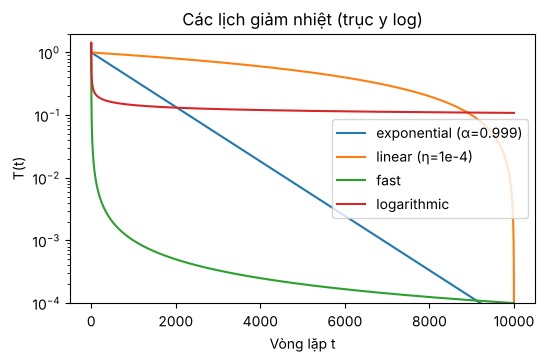

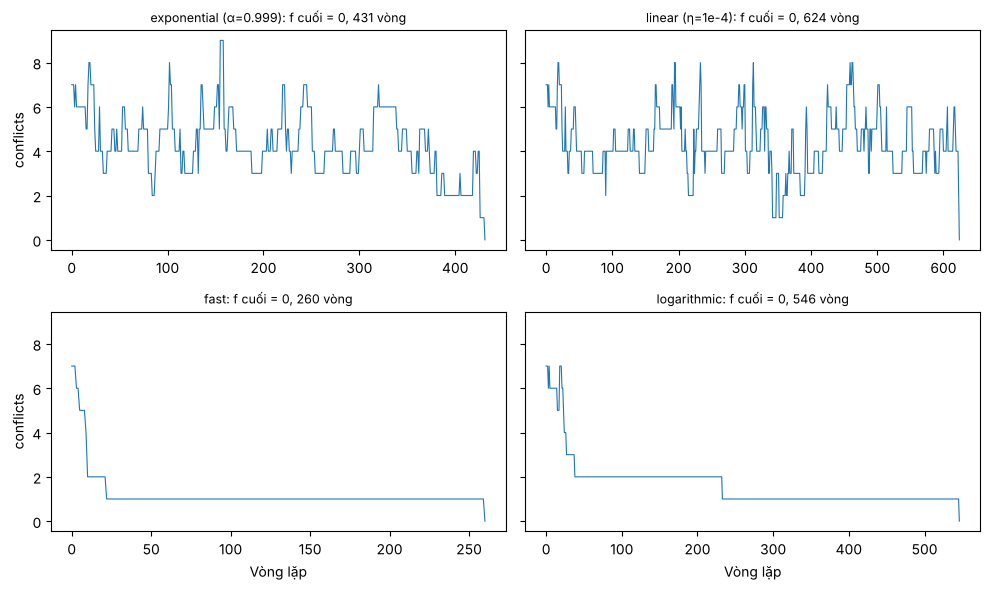

,Schedule,n,Avg. time (ms),Avg. conflicts,% optimal,Avg. iters
0,exponential (α=0.999),8,19.87,0.01,99.0,1346.96
1,linear (η=1e-4),8,35.75,0.00,100.0,2513.52
2,fast,8,10.53,0.01,99.0,741.88
3,logarithmic,8,14.82,0.03,97.0,1048.92
4,exponential (α=0.999),12,61.60,0.01,99.0,3433.19
5,linear (η=1e-4),12,141.84,0.16,84.0,7875.34
6,fast,12,41.48,0.04,96.0,2232.74
7,logarithmic,12,42.33,0.04,96.0,2325.50


,T0,alpha,Avg. time (ms),Avg. conflicts,% optimal,Avg. iters
0,0.5,0.990,7.11,0.28,72.0,484.0
1,0.5,0.995,8.91,0.07,93.0,552.0
2,0.5,0.999,14.51,0.03,97.0,977.0
3,1.0,0.990,8.56,0.34,66.0,567.0
4,1.0,0.995,11.68,0.09,91.0,745.0
5,1.0,0.999,22.36,0.01,99.0,1347.0
6,2.0,0.990,9.09,0.26,74.0,566.0
7,2.0,0.995,12.36,0.14,86.0,897.0
8,2.0,0.999,23.72,0.00,100.0,1643.0


In [9]:
# Các lịch giảm nhiệt (t = số vòng lặp đã chạy)
def temperature_exponential(t, T0=1.0, alpha=0.999): return T0 * alpha ** t
def temperature_linear(t, T0=1.0, eta=1e-4):         return max(T0 - eta * t, 0.0)
def temperature_fast(t, T0=1.0):                     return T0 / (1 + t)
def temperature_logarithmic(t, T0=1.0):              return T0 if t == 0 else T0 / math.log(1 + t)  # định nghĩa cho t > 0

def simulated_annealing(board, schedule=temperature_exponential, max_iter=10000, T_min=1e-4):
    """SA: sinh 1 lân cận ngẫu nhiên; delta = f_mới - f_cũ.
    delta < 0 -> chấp nhận; delta >= 0 -> chấp nhận với xác suất exp(-delta/T). Dừng khi f = 0, T < T_min hoặc hết max_iter."""
    board = np.array(board).copy()
    n = len(board)
    f = conflicts(board); evals = 1; steps = 0; it = 0
    history = [f]
    while f > 0 and it < max_iter:
        T = schedule(it)
        if T < T_min: break
        it += 1
        col = np.random.randint(n)
        row = np.random.randint(n - 1)
        if row >= board[col]: row += 1
        old = board[col]; board[col] = row
        nf = conflicts(board); evals += 1
        delta = nf - f
        if delta < 0 or np.random.rand() < math.exp(-delta / T):
            f = nf; steps += 1                       # chấp nhận (kể cả nước xấu hơn)
        else:
            board[col] = old
        history.append(f)
    return {"board": board, "f": f, "steps": steps, "iters": it, "evals": evals, "history": history}

# --- Đồ thị các lịch nhiệt (cùng T0 = 1, cùng 10000 vòng lặp) ---
schedules = {"exponential (α=0.999)": temperature_exponential, "linear (η=1e-4)": temperature_linear,
             "fast": temperature_fast, "logarithmic": temperature_logarithmic}
t = np.arange(0, 10000)
plt.figure(figsize=(6, 3.5))
for name, s in schedules.items(): plt.plot(t, [s(i) for i in t], label=name)
plt.xlabel("Vòng lặp t"); plt.ylabel("T(t)"); plt.yscale("log"); plt.ylim(1e-4, 2)
plt.title("Các lịch giảm nhiệt (trục y log)"); plt.legend(); plt.show()

# --- Quá trình tìm kiếm (1 lần chạy, n = 8, cùng bàn cờ ban đầu) ---
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for ax, (name, s) in zip(axes.ravel(), schedules.items()):
    np.random.seed(5)
    r = simulated_annealing(random_board(8), schedule=s)
    ax.plot(r["history"], lw=0.8); ax.set_title(f"{name}: f cuối = {r['f']}, {r['iters']} vòng", fontsize=9)
for ax in axes[1]: ax.set_xlabel("Vòng lặp")
for ax in axes[:, 0]: ax.set_ylabel("conflicts")
plt.tight_layout(); plt.show()

# --- So sánh lịch nhiệt: 100 lần chạy, n = 8 và n = 12 ---
def test_sa(n, schedule, runs=100, seed=0):
    rows = []
    for i in range(runs):
        np.random.seed(seed + i)
        t0 = time.perf_counter()
        r = simulated_annealing(random_board(n), schedule=schedule)
        rows.append({"ms": (time.perf_counter() - t0) * 1000, "f": r["f"], "iters": r["iters"]})
    d = pd.DataFrame(rows)
    return {"Avg. time (ms)": d.ms.mean(), "Avg. conflicts": d.f.mean(),
            "% optimal": 100 * (d.f == 0).mean(), "Avg. iters": d.iters.mean()}

rows = [{"Schedule": name, "n": n, **test_sa(n, s)} for n in (8, 12) for name, s in schedules.items()]
display(pd.DataFrame(rows).round(2))

# --- Ảnh hưởng của nhiệt độ đầu T0 và tốc độ làm nguội α (lịch mũ, n = 8) ---
from functools import partial
rows = []
for T0 in (0.5, 1, 2):
    for alpha in (0.99, 0.995, 0.999):
        s = partial(temperature_exponential, T0=T0, alpha=alpha)
        rows.append({"T0": T0, "alpha": alpha, **test_sa(8, s)})
display(pd.DataFrame(rows).round({'Avg. time (ms)': 2, 'Avg. conflicts': 2, '% optimal': 1, 'Avg. iters': 0}))

### Nhận xét (Task 5)

**Cách cài đặt:** SA sinh một lân cận ngẫu nhiên như Task 3, với Δ = f_mới − f_cũ: nếu Δ < 0 thì chấp nhận, nếu Δ ≥ 0 thì chấp nhận với xác suất exp(−Δ/T). T giảm theo lịch nhiệt; dừng khi f = 0, T < T_min hoặc hết 10000 vòng lặp. Vì Δ là số nguyên (1, 2, ...) nên dùng T0 = 1: lúc đầu bước xấu hơn 1 đơn vị được chấp nhận với p ≈ e^(−1) ≈ 0.37.

**Các lịch nhiệt (cùng T0 = 1, cùng ngân sách 10000 vòng):**

* **Tuyến tính** giữ T cao nhất (T ≥ 0.3 đến t ≈ 7000) rồi giảm đột ngột về 0 ở cuối, nên chấp nhận bước xấu lâu nhất. Với n = 12, nó mất nhiều vòng lặp nhất (≈ 7900) và chỉ đạt 84%, vì phần lớn ngân sách bị dùng khi còn quá nóng và giai đoạn nguội cuối quá ngắn.
* **Mũ (α = 0.999)** giữ T ≥ 0.3 đến t ≈ 1200 rồi nguội dần và mượt, cân bằng tốt nhất: 99% ở cả n = 8 và n = 12.
* **Fast** (T0/(1+t)) và **logarithmic** nguội rất nhanh ngay từ đầu (T < 0.3 sau chỉ vài chục vòng) nên rẻ nhất (≈ 740–1050 vòng với n = 8), vẫn đạt 96–99% vì n-Queens có rất nhiều nghiệm. Logarithmic có "đuôi" dài (T ≈ 0.1 ở t = 10000) nhưng với T này xác suất chấp nhận bước xấu gần bằng 0 nên không giúp nhiều.
* **Ảnh hưởng của tham số (lịch mũ, n = 8):** làm nguội nhanh (α = 0.99) chỉ đạt 66–74%, α = 0.995 đạt 86–93%, α = 0.999 đạt 97–100%. T0 lớn hơn cho kết quả tốt hơn khi α đủ lớn (T0 = 2, α = 0.999: 100%), đổi lại tốn nhiều vòng lặp hơn. Đây là đánh đổi giữa chất lượng và thời gian.

**Lựa chọn cho các thí nghiệm sau:** lịch mũ với T0 = 1, α = 0.999. Nếu cần nhanh hơn thì dùng fast.

In [10]:
# Bài 4: tỉ lệ SA tìm được lời giải không xung đột trên n = 4 và n = 8.
# Điều kiện thống nhất cho mọi lịch nhiệt: T0 = 1, max_iter = 10000, T_min = 1e-4, seed 0..99 (100 lần chạy).
rows = [{"Schedule": name, "n": n, **test_sa(n, s, runs=100)} for n in (4, 8) for name, s in schedules.items()]
display(pd.DataFrame(rows).round(2))

,Schedule,n,Avg. time (ms),Avg. conflicts,% optimal,Avg. iters
0,exponential (α=0.999),4,0.68,0.00,100.0,60.21
1,linear (η=1e-4),4,0.74,0.00,100.0,65.01
2,fast,4,0.51,0.00,100.0,42.84
3,logarithmic,4,0.55,0.00,100.0,46.09
4,exponential (α=0.999),8,19.48,0.01,99.0,1346.96
5,linear (η=1e-4),8,35.59,0.00,100.0,2513.52
6,fast,8,9.76,0.01,99.0,741.88
7,logarithmic,8,13.87,0.03,97.0,1048.92


### Nhận xét Bài 4: Random Restart và Simulated Annealing

* **Thiết lập thống nhất:** seed 0..99 cho 100 lần chạy, cùng bàn cờ ban đầu cho mọi cấu hình; SA luôn dùng T0 = 1 (trừ khi khảo sát T0), ngân sách `max_iter` = 10000 và điều kiện dừng f = 0, T < T_min = 1e-4 hoặc hết ngân sách.
* **Tỉ lệ tìm được lời giải không xung đột (SA, 100 lần chạy):** n = 4 là 100% với cả bốn lịch nhiệt; n = 8 là 97–100% (xem bảng trên), trong khi một lần chạy Hill Climbing đơn lẻ chỉ đạt 17–20%.
* **Nhiệt độ đầu T0 và tốc độ làm nguội α (lịch mũ, n = 8):** α quyết định mạnh hơn T0. Làm nguội nhanh (α = 0.99) chỉ đạt 66–74%, α = 0.995 đạt 86–93%, α = 0.999 đạt 97–100%. T0 lớn hơn (2) với α = 0.999 cho 100% nhưng tốn nhiều vòng lặp nhất (≈ 1643 so với ≈ 977 khi T0 = 0.5). Làm nguội chậm cho SA nhiều thời gian chấp nhận bước xấu để thoát cực trị cục bộ, đổi lại tốn thêm vòng lặp.
* **Random Restart so với SA (n = 8):** cả hai đều tiến tới ≈ 100% với thời gian cùng bậc (cả hai cỡ vài chục ms ở n = 8; số cụ thể phụ thuộc máy). Random Restart chỉ chạy lại từ đầu và bỏ hết thông tin cũ; SA đi tiếp trên cùng một đường đi và tự thoát cực trị, nên mở rộng tốt hơn khi p của một lần chạy đơn lẻ giảm (n lớn: 85–100% đến n = 20, trong khi Hill Climbing gần 0%).

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [11]:
def run_experiment(algo, n, runs=100, seed=0, **kw):
    """Chạy `algo` `runs` lần, mỗi lần một bàn cờ ngẫu nhiên khác nhau (seed cố định -> tái lập được)."""
    rows = []
    for i in range(runs):
        np.random.seed(seed + i)
        board = random_board(n)
        t0 = time.perf_counter()
        res = algo(board, **kw)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"ms": ms, "f": res["f"], "steps": res["steps"], "evals": res["evals"]})
    d = pd.DataFrame(rows)
    return {"Avg. run time (ms)": d.ms.mean(), "Avg. number of conflicts": d.f.mean(),
            "% of runs ending in optimal solution": 100 * (d.f == 0).mean(),
            "Avg. steps": d.steps.mean(), "Avg. evals": d.evals.mean()}

algos = {"Steepest asc. HC": steepest_ascent,
         "Ineff. Stochastic HC": stochastic_inefficient,
         "Efficient Stochastic HC": stochastic_efficient,
         "Simulated Annealing": simulated_annealing}   # SA dùng lịch mũ T0=1, alpha=0.999

rows = []
for n in (4, 8):
    for name, fn in algos.items():
        rows.append({"Algorithm": name, "Board size": n, **run_experiment(fn, n, runs=100)})
results = pd.DataFrame(rows)
display(results.round(3))

,Algorithm,Board size,Avg. run time (ms),Avg. number of conflicts,% of runs ending in optimal solution,Avg. steps,Avg. evals
0,Steepest asc. HC,4,0.131,0.60,48.0,1.48,25.00
1,Ineff. Stochastic HC,4,0.159,0.73,40.0,1.86,30.52
2,Efficient Stochastic HC,4,0.468,0.76,36.0,1.72,49.64
3,Simulated Annealing,4,0.615,0.00,100.0,33.11,61.21
4,Steepest asc. HC,8,1.761,1.13,19.0,3.31,231.72
5,Ineff. Stochastic HC,8,2.515,1.20,20.0,4.98,324.68
6,Efficient Stochastic HC,8,6.316,1.20,17.0,4.96,442.83
7,Simulated Annealing,8,19.196,0.01,99.0,324.16,1347.96


### Nhận xét bảng kết quả (Task 6)

100 lần chạy cho mỗi ô, mỗi lần một bàn cờ ngẫu nhiên khác nhau (seed 0..99, tái lập được). Cột `Avg. evals` là số lần gọi `conflicts()`, đại diện cho chi phí tính toán độc lập với máy.

| Algorithm | n | Avg. conflicts | % optimal |
|---|---|---|---|
| Steepest asc. HC | 4 | 0.60 | 48% |
| Ineff. Stochastic HC | 4 | 0.73 | 40% |
| Efficient Stochastic HC | 4 | 0.76 | 36% |
| Simulated Annealing | 4 | 0.00 | 100% |
| Steepest asc. HC | 8 | 1.13 | 19% |
| Ineff. Stochastic HC | 8 | 1.20 | 20% |
| Efficient Stochastic HC | 8 | 1.20 | 17% |
| Simulated Annealing | 8 | 0.01 | 99% |

Thời gian chạy (xem cột `Avg. run time (ms)` ở bảng trên, dao động nhẹ giữa các lần chạy theo tải máy) có thứ tự ổn định: Steepest ≈ Ineff. Stochastic < Efficient Stochastic < SA; với n = 8 SA chậm hơn Steepest khoảng 7–10 lần.

* Ba biến thể Hill Climbing có chất lượng gần như nhau (chỉ 17–20% thành công khi n = 8) vì cùng bị kẹt ở các cực trị cục bộ. Sự khác nhau giữa chúng nhỏ hơn dao động ngẫu nhiên.
* **Chất lượng so với chi phí:** Steepest rẻ nhất về thời gian và số lần gọi `conflicts()` (≈ 232 với n = 8). Ineff. Stochastic cần nhiều bước hơn (≈ 5 so với 3.3) vì chọn ngẫu nhiên thay vì chọn nước tốt nhất. Efficient Stochastic tuy mỗi lần thử chỉ tốn 1 lần đánh giá nhưng phải trả `patience` ≈ 450 lần thử thất bại liên tiếp để kết luận đã kẹt, nên tổng cộng tốn ≈ 443 lần gọi và chậm nhất trong ba biến thể. Nó chỉ thực sự có lợi khi số lân cận lớn hơn nhiều và có thể dùng `patience` nhỏ hơn.
* **Simulated Annealing** đạt 99–100% nhờ chấp nhận bước xấu để thoát cực trị cục bộ, đổi lại tốn nhiều thời gian hơn khoảng 3–10 lần (≈ 1350 lần gọi `conflicts()` với n = 8). Kết quả của SA phụ thuộc vào lịch nhiệt (xem Task 5).

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

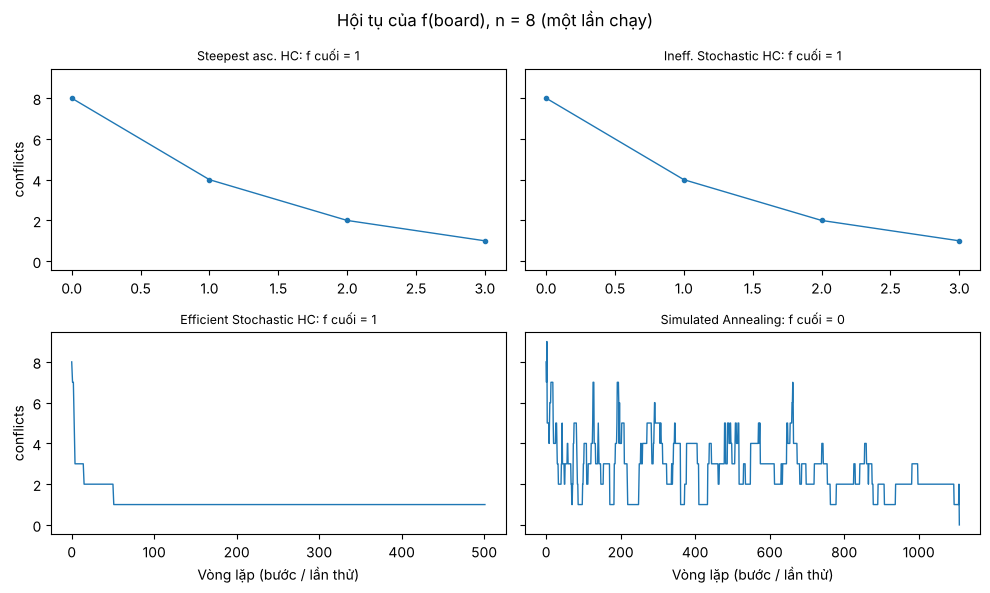

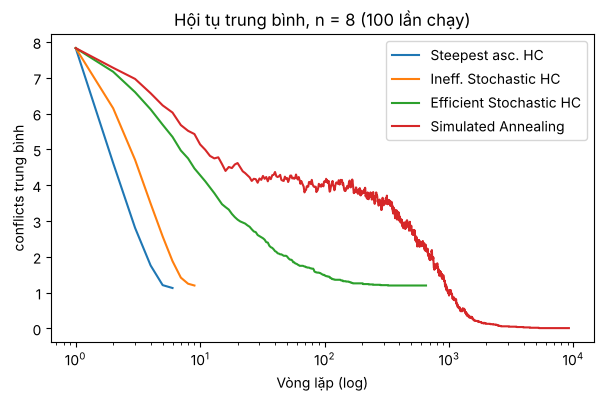

Algorithm
Steepest asc. HC           81.0
Ineff. Stochastic HC       80.0
Efficient Stochastic HC    83.0
Simulated Annealing         1.0


In [12]:
# (a) Một lần chạy đại diện (n = 8, cùng bàn cờ ban đầu cho cả 4 thuật toán)
seed = 3
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for ax, (name, fn) in zip(axes.ravel(), algos.items()):
    np.random.seed(seed)
    r = fn(random_board(8))
    ax.plot(r["history"], marker="o" if len(r["history"]) < 30 else None, ms=3, lw=1)
    ax.set_title(f"{name}: f cuối = {r['f']}", fontsize=9)
for ax in axes[1]: ax.set_xlabel("Vòng lặp (bước / lần thử)")
for ax in axes[:, 0]: ax.set_ylabel("conflicts")
plt.suptitle("Hội tụ của f(board), n = 8 (một lần chạy)"); plt.tight_layout(); plt.show()

# (b) Trung bình 100 lần chạy (trục x log; chuỗi ngắn được kéo dài bằng giá trị cuối)
plt.figure(figsize=(7, 4))
for name, fn in algos.items():
    H = []
    for i in range(100):
        np.random.seed(i); H.append(fn(random_board(8))["history"])
    L = max(map(len, H))
    M = np.array([h + [h[-1]] * (L - len(h)) for h in H])
    plt.plot(np.arange(1, L + 1), M.mean(axis=0), label=name)
plt.xscale("log"); plt.xlabel("Vòng lặp (log)"); plt.ylabel("conflicts trung bình")
plt.title("Hội tụ trung bình, n = 8 (100 lần chạy)"); plt.legend(); plt.show()

# (c) Tỉ lệ bị kẹt ở cực trị cục bộ (kết thúc với f > 0)
stuck = results[results["Board size"] == 8].set_index("Algorithm")["% of runs ending in optimal solution"]
print((100 - stuck).round(1).rename("% runs kẹt (n=8)").to_string())

### Nhận xét hội tụ

* **Steepest ascent và Ineff. Stochastic:** giảm rất nhanh ngay ở các bước đầu (ví dụ f từ 8 xuống 4 rồi 2 chỉ sau 2 bước), mỗi bước cắt khoảng một nửa số xung đột, nhưng chỉ sau 3–5 bước thì không còn nước cải thiện và thuật toán dừng. Đây là hiện tượng **dừng sớm** ở cực trị cục bộ.
* **Efficient Stochastic:** cải thiện nhanh trong khoảng 10–50 lần thử đầu, sau đó là một **đoạn nằm ngang (plateau)** dài đúng `patience` lần thử thất bại trước khi dừng. Đoạn này là phần chi phí chỉ để xác nhận bị kẹt (xem đồ thị).
* **Simulated Annealing:** f dao động mạnh ở giai đoạn nóng (tăng lên 5–7 rồi giảm lại), tức là liên tục thoát khỏi các cực trị cục bộ; f chỉ ổn định khi T giảm và chạm 0 sau khoảng 1000 vòng. Cải thiện ban đầu chậm hơn Hill Climbing nhưng tiến tới nghiệm tốt.
* **Mức độ bị kẹt (n = 8):** khoảng 81% (Steepest), 80% (Ineff. Stochastic), 83% (Efficient Stochastic) số lần chạy kết thúc với f > 0, còn SA chỉ khoảng 1%. Đồ thị trung bình 100 lần chạy cho thấy ba biến thể Hill Climbing đều dừng ở mức trung bình ≈ 1.1–1.2 xung đột, còn SA tiến về 0.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

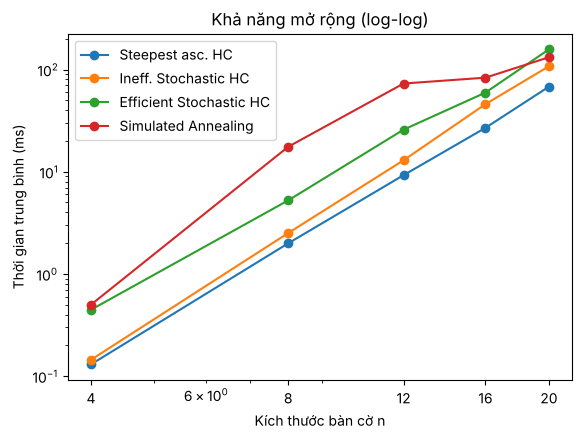

Thời gian trung bình (ms):


,n=4,n=8,n=12,n=16,n=20,slope k (O(n^k))
Steepest asc. HC,0.13,1.99,9.26,26.87,67.93,3.87
Ineff. Stochastic HC,0.14,2.51,12.94,45.83,107.61,4.12
Efficient Stochastic HC,0.45,5.24,25.80,59.48,157.50,3.62
Simulated Annealing,0.50,17.54,72.95,83.24,131.86,3.46


% lần chạy tìm được nghiệm tối ưu:


,n=4,n=8,n=12,n=16,n=20
Steepest asc. HC,50.0,20.0,5.0,10.0,0.0
Ineff. Stochastic HC,40.0,30.0,0.0,0.0,0.0
Efficient Stochastic HC,35.0,30.0,0.0,5.0,0.0
Simulated Annealing,100.0,100.0,100.0,100.0,85.0


In [13]:
sizes = [4, 8, 12, 16, 20]
scal, succ = {}, {}
for name, fn in algos.items():
    res_n = [run_experiment(fn, n, runs=20) for n in sizes]
    scal[name] = [r["Avg. run time (ms)"] for r in res_n]
    succ[name] = [r["% of runs ending in optimal solution"] for r in res_n]

plt.figure(figsize=(6.5, 4.5))
for name, tms in scal.items(): plt.loglog(sizes, tms, "o-", label=name)
plt.xlabel("Kích thước bàn cờ n"); plt.ylabel("Thời gian trung bình (ms)")
plt.xticks(sizes, sizes); plt.title("Khả năng mở rộng (log-log)"); plt.legend(); plt.show()

# Độ dốc của đường thẳng log-log: thời gian ~ n^k  ->  k là số mũ trong O(n^k)
slopes = {name: np.polyfit(np.log(sizes), np.log(tms), 1)[0] for name, tms in scal.items()}
tab = pd.DataFrame(scal, index=[f"n={n}" for n in sizes]).T
tab["slope k (O(n^k))"] = pd.Series(slopes)
print("Thời gian trung bình (ms):"); display(tab.round(2))
print("% lần chạy tìm được nghiệm tối ưu:"); display(pd.DataFrame(succ, index=[f"n={n}" for n in sizes]).T.round(1))

### Nhận xét khả năng mở rộng

Đồ thị log-log cho thấy thời gian tăng gần như một đường thẳng, độ dốc k là số mũ của hàm O(n^k) thực nghiệm:

| Thuật toán | Độ dốc k | Giải thích |
|---|---|---|
| Steepest asc. HC | ≈ 4 | Mỗi bước tốn n(n−1) lần gọi `conflicts()` × O(n) = O(n³), cộng với số bước tăng theo n, nên gần O(n⁴). |
| Ineff. Stochastic HC | ≈ 4 | Cùng chi phí mỗi bước như Steepest. |
| Efficient Stochastic HC | ≈ 3.2 | `patience` ≈ 2n²·ln n lần thử, mỗi lần O(n), tức là cỡ O(n³ log n). |
| Simulated Annealing | ≈ 3.5 | Mỗi vòng chỉ tốn O(n) (1 lần gọi `conflicts()`), nhưng số vòng lặp cần để thành công tăng theo n. |

**Lưu ý khi đọc kết quả:** đây là ước lượng thực nghiệm trong khoảng n = 4..20, bị ảnh hưởng bởi hằng số, chi phí của Python và việc có lần chạy kết thúc sớm do thành công; chỉ nên coi k là ≈ 3–4 (thời gian tuyệt đối phụ thuộc máy) (giá trị chính xác thay đổi nhẹ giữa các lần chạy do nhiễu thời gian ở n nhỏ; xem bảng phía trên).

**Thuật toán nào mở rộng tốt nhất?** Xét riêng thời gian thì Steepest nhanh nhất (≈ 80 ms ở n = 20), nhưng nó gần như **không tìm được nghiệm** (0–10% khi n ≥ 12). Simulated Annealing tốn khoảng gấp đôi thời gian (≈ 150 ms ở n = 20) nhưng vẫn tìm được nghiệm tối ưu 85–100% số lần chạy với mọi n khảo sát. Vì vậy với bài toán lớn, SA là lựa chọn tốt nhất xét trên cả chất lượng lẫn thời gian, còn các Hill Climbing thuần túy cần thêm Random Restart. Chi phí mỗi vòng lặp của SA thấp (O(n)) nên về lý thuyết nó mở rộng tốt hơn các thuật toán phải duyệt toàn bộ lân cận.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

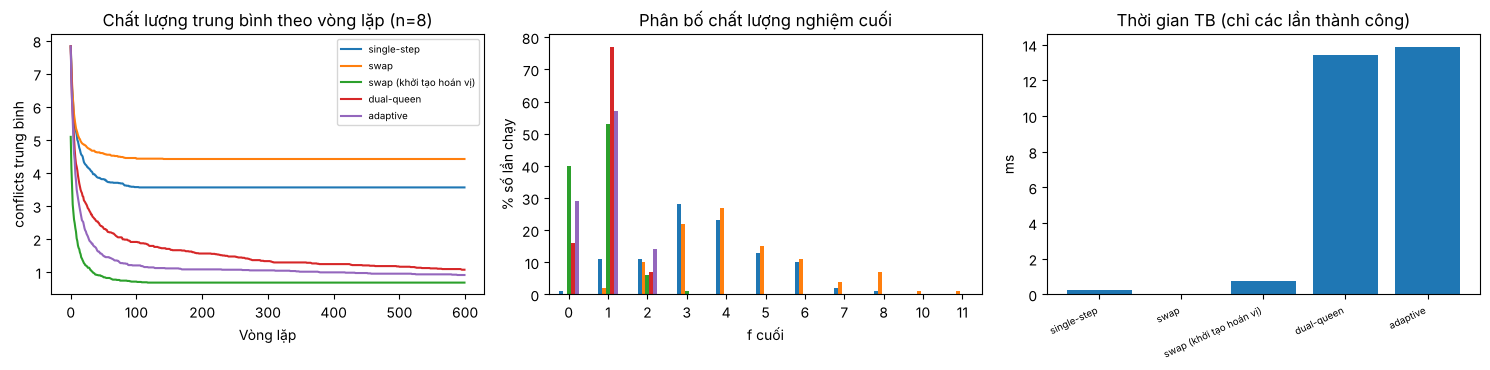

,% optimal,Avg. conflicts,Avg. time success (ms)
single-step,1.0,3.56,0.25
swap,0.0,4.42,NaN
swap (khởi tạo hoán vị),40.0,0.68,0.74
dual-queen,16.0,0.91,13.41
adaptive,29.0,0.85,13.88


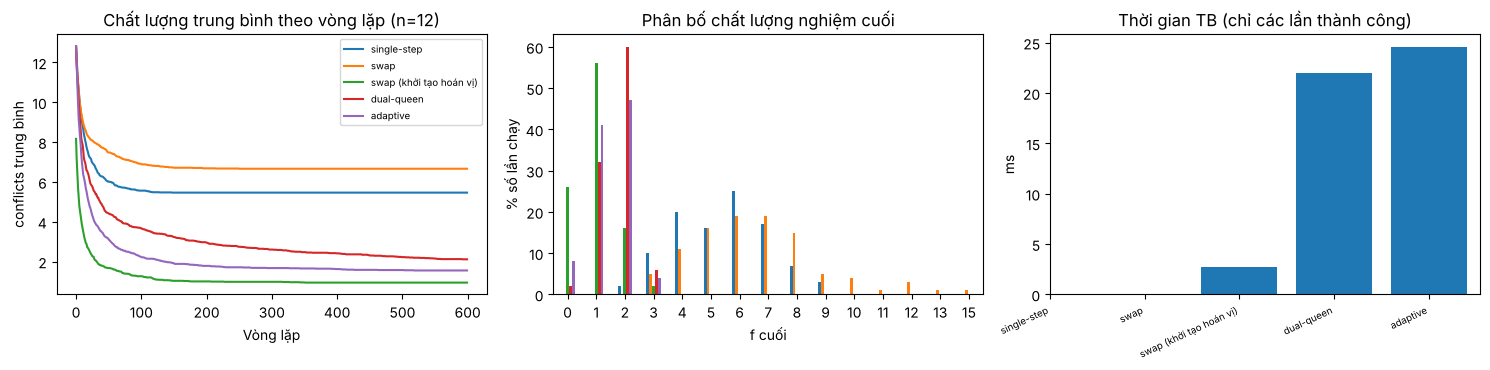

,% optimal,Avg. conflicts,Avg. time success (ms)
single-step,0.0,5.46,NaN
swap,0.0,6.66,NaN
swap (khởi tạo hoán vị),26.0,0.94,2.69
dual-queen,2.0,1.70,21.94
adaptive,8.0,1.47,24.58


In [14]:
# ---------- 4 toán tử di chuyển ----------
def other_row(b, c):
    """Một hàng ngẫu nhiên khác hàng hiện tại của cột c."""
    r = np.random.randint(len(b) - 1)
    return r + 1 if r >= b[c] else r

def op_single_step(board):
    """Dịch một quân hậu lên/xuống đúng 1 ô."""
    b = board.copy(); n = len(b); c = np.random.randint(n)
    d = 1 if b[c] == 0 else (-1 if b[c] == n - 1 else np.random.choice([-1, 1]))
    b[c] += d; return b

def op_swap(board):
    """Đổi hàng của hai cột ngẫu nhiên."""
    b = board.copy(); i, j = np.random.choice(len(b), 2, replace=False)
    b[i], b[j] = b[j], b[i]; return b

def op_dual(board):
    """Chọn hai quân hậu, chuyển cả hai sang hàng mới (ngẫu nhiên)."""
    b = board.copy(); i, j = np.random.choice(len(b), 2, replace=False)
    b[i] = other_row(b, i); b[j] = other_row(b, j); return b

def queen_conflicts(board):
    """Số quân hậu khác đang tấn công từng quân hậu (vector độ dài n)."""
    b = np.asarray(board); idx = np.arange(len(b))
    attack = (b[:, None] == b[None, :]) | (np.abs(b[:, None] - b[None, :]) == np.abs(idx[:, None] - idx[None, :]))
    return attack.sum(axis=1) - 1

def op_adaptive(board, p_random=0.2):
    """Thích nghi: 80% chọn quân hậu theo xác suất tỉ lệ với số xung đột của nó rồi dời sang hàng khác;
    20% chọn ngẫu nhiên một trong 3 toán tử trên (để không bị kẹt khi tập trung quá hẹp)."""
    if np.random.rand() < p_random:
        return np.random.choice([op_single_step, op_swap, op_dual])(board)
    w = queen_conflicts(board) + 0.1
    c = np.random.choice(len(board), p=w / w.sum())
    b = board.copy(); b[c] = other_row(b, c); return b

def stochastic_hc_op(board, operator, patience=1000, max_iter=20000):
    """Efficient Stochastic HC với toán tử lân cận tuỳ chọn; cùng patience cho mọi toán tử để so sánh công bằng."""
    board = np.array(board).copy()
    f = conflicts(board); evals = 1; steps = 0; fails = 0; it = 0
    history = [f]
    while f > 0 and fails < patience and it < max_iter:
        it += 1
        new = operator(board); nf = conflicts(new); evals += 1
        if nf < f: board, f = new, nf; steps += 1; fails = 0
        else: fails += 1
        history.append(f)
    return {"board": board, "f": f, "steps": steps, "iters": it, "evals": evals, "history": history}

# Swap giữ nguyên tập hợp các hàng -> thêm biến thể khởi tạo bằng HOÁN VỊ (mỗi hàng đúng 1 quân)
ops = {"single-step": (op_single_step, False), "swap": (op_swap, False),
       "swap (khởi tạo hoán vị)": (op_swap, True), "dual-queen": (op_dual, False), "adaptive": (op_adaptive, False)}

def run_ops(n, runs=100, seed=0):
    out = {}
    for name, (op, perm) in ops.items():
        recs = []
        for i in range(runs):
            np.random.seed(seed + i)
            b = np.random.permutation(n) if perm else random_board(n)
            t0 = time.perf_counter()
            r = stochastic_hc_op(b, op)
            recs.append({"f": r["f"], "ms": (time.perf_counter() - t0) * 1000, "history": r["history"]})
        out[name] = recs
    return out

def plot_ops(n, out, maxlen=600):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, recs in out.items():                                   # (1) f trung bình theo vòng lặp
        H = np.array([h["history"][:maxlen] + [h["history"][-1]] * max(0, maxlen - len(h["history"])) for h in recs])
        ax[0].plot(H.mean(axis=0), label=name)
    ax[0].set(xlabel="Vòng lặp", ylabel="conflicts trung bình", title=f"Chất lượng trung bình theo vòng lặp (n={n})"); ax[0].legend(fontsize=7)
    fin = pd.DataFrame({name: pd.Series([r["f"] for r in recs]).value_counts() for name, recs in out.items()}).fillna(0).sort_index()
    (fin / fin.sum() * 100).plot.bar(ax=ax[1], rot=0, legend=False)  # (2) phân bố f cuối
    ax[1].set(xlabel="f cuối", ylabel="% số lần chạy", title="Phân bố chất lượng nghiệm cuối")
    tm = {name: np.mean([r["ms"] for r in recs if r["f"] == 0]) if any(r["f"] == 0 for r in recs) else np.nan
          for name, recs in out.items()}                             # (3) thời gian của các lần thành công
    ax[2].bar(range(len(tm)), list(tm.values())); ax[2].set_xticks(range(len(tm))); ax[2].set_xticklabels(list(tm), rotation=25, ha="right", fontsize=7)
    ax[2].set(ylabel="ms", title="Thời gian TB (chỉ các lần thành công)")
    plt.tight_layout(); plt.show()
    return pd.DataFrame({name: {"% optimal": 100 * np.mean([r["f"] == 0 for r in recs]),
                                "Avg. conflicts": np.mean([r["f"] for r in recs]),
                                "Avg. time success (ms)": tm[name]} for name, recs in out.items()}).T.round(2)

for n in (8, 12):
    out = run_ops(n)
    display(plot_ops(n, out))

### Thảo luận (nâng cao)

Mọi toán tử dùng cùng Efficient Stochastic HC, cùng `patience = 1000` và cùng 100 bàn cờ ban đầu (seed 0..99), nên các khác biệt dưới đây đến từ toán tử. Lưu ý kết luận phụ thuộc vào `patience` cố định này.

| Toán tử | Kích thước lân cận (n = 8) | % optimal n=8 | % optimal n=12 | Nhận xét |
|---|---|---|---|---|
| single-step | ≈ 2n = 16 | 1% | 0% | Lân cận quá nhỏ, 1000 lần thử đã thử hết nên dừng ngay ở cực trị cục bộ. Rất nhanh nhưng chất lượng kém. |
| swap (từ bàn ngẫu nhiên) | n(n−1)/2 = 28 | 0% | 0% | Hoán đổi hàng **không thay đổi tập hợp các hàng**, nên không thể gỡ xung đột cùng hàng của bàn ngẫu nhiên. |
| swap (khởi tạo hoán vị) | 28 | **40%** | **26%** | Khởi tạo hoán vị loại bỏ xung đột hàng, không gian tìm kiếm giảm từ nⁿ xuống n!, nên tốt nhất với cả hai kích thước. |
| dual-queen | C(n,2)·(n−1)² = 1372 | 16% | 2% | Lân cận lớn, mạnh hơn single-step vì di chuyển hai quân cùng lúc có thể thoát cực trị, nhưng 1000 lần thử chỉ phủ một phần lân cận. |
| adaptive | thay đổi | 29% | 8% | Tập trung vào quân hậu có nhiều xung đột và cần ít lần đánh giá hơn dual-queen, nên tốt hơn dual-queen ở cả hai kích thước. Đổi lại mỗi vòng lặp chậm hơn do tính xung đột từng quân. |

**Bài học:** (1) kích thước lân cận là một đánh đổi: quá nhỏ thì dễ kẹt, quá lớn thì tốn nhiều lần thử mới tìm được nước tốt; (2) toán tử phải phù hợp với biểu diễn trạng thái, ví dụ swap chỉ hiệu quả khi biểu diễn là hoán vị; (3) dùng thông tin của bài toán (quân nào đang xung đột) giúp tìm kiếm có định hướng hơn so với chọn ngẫu nhiên. Với n = 12 mọi toán tử đều giảm hiệu quả, cho thấy Hill Climbing thuần túy khó mở rộng dù đổi toán tử.

---
### Kết luận chung

* Ba biến thể Hill Climbing nhanh nhưng dễ kẹt ở cực trị cục bộ (chỉ khoảng 20% thành công với n = 8, gần 0% với n ≥ 12); chúng gần như tương đương về chất lượng và khác nhau chủ yếu ở chi phí mỗi bước.
* Random Restart đưa tỉ lệ thành công lên 100% với n = 8 với chi phí khoảng 1/p lần chạy.
* Simulated Annealing đạt 99–100% với n ≤ 12 và vẫn 85% với n = 20, chấp nhận chi phí thời gian cao hơn; chất lượng phụ thuộc vào lịch nhiệt, trong đó lịch mũ α = 0.999 cân bằng tốt nhất.
* Hạn chế: các kết quả dùng tham số cố định (`patience`, T0, α, ngân sách vòng lặp) và thời gian chạy phụ thuộc máy; số lần chạy 100 (20 cho thí nghiệm mở rộng) nên các chênh lệch vài phần trăm không có ý nghĩa thống kê.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [15]:
# Code and description go here